# 01-操作系统基础、多任务与资源调度

> CPU 负责执行当前指令，操作系统负责组织任务和管理资源。本篇先理解“为什么需要调度、切换时保留什么、共享资源怎样协调”，再为后续在 STC 单片机上实现任务切换做准备。

这是《自己动手写嵌入式操作系统》五篇笔记中的第 01 篇。


## 1. 学习范围与资料说明

本篇按课程视频 **01—08** 的主题整理：

| 视频 | 目录标题 | 本篇重点 |
|---|---|---|
| 01 | 自己动手写操作系统 | 学习目标：理解并实现简化的多任务机制 |
| 02 | 操作系统相关概念 | 任务、资源、顺序执行与多任务 |
| 03 | 高级操作系统特性 | 认识功能边界，不把完整桌面系统当作最小要求 |
| 04 | 时间片轮转和上下文切换 | CPU 使用时间与任务状态 |
| 05 | 操作系统与资源调度 | 调度谁运行、怎样协调资源 |
| 06 | 资源调度与资源争抢 | 共享数据和外设的访问关系 |
| 07 | 中断和实时操作系统 | 事件响应、截止时间与实时性 |
| 08 | 操作系统概念总结 | 把概念串成完整框架 |

**核对范围：**视频目录已核对；本篇核对了 16 页配套讲义中的第 **2、12、13 页**，其中第 12—13 页是课程概念总结。视频未逐段观看或转录。本篇引用这几页中的定义与幼儿园类比；状态模型、计算例子、伪代码及更严谨的工程说明就地标为“补充理解”或“自编例子”。

STC 内存布局、SP 的具体修改、`loadtask` 与调度器代码留给第 02—03 篇。本篇不把通用伪代码当作课程源码。

学完后，应能够解释：单核多任务怎样运行、一次任务切换需要保留什么、资源争用为什么不等于程序自动出错，以及“运行得快”为什么不等于“满足实时要求”。


## 2. 从“执行指令”走到“安排任务”

前面的计算机底层原理笔记已经说明：PC 指向指令，CPU 取指、译码、执行，并更新寄存器和内存。

现在增加一个问题：设备既要读取传感器，又要通信、显示和控制电机，**当前应该继续哪项工作？**

```text
任务 A：传感器采样 ─┐
任务 B：串口通信   ─┼→ 调度决策 → CPU 执行被选中的任务
任务 C：电机控制   ─┘
```

**补充理解：**CPU 的硬件控制单元与操作系统调度器处于不同层次：

| 对象 | 决定什么 |
|---|---|
| CPU 控制单元 | 一条指令内部怎样传送数据、运算和更新状态 |
| 操作系统调度器 | 哪个可运行的任务获得 CPU 执行机会 |

任务切换最终也依靠机器指令与硬件机制完成。操作系统并不取代 CPU 控制单元。


## 3. 操作系统是什么，为什么需要它？

讲义第 2 页把操作系统概括为：**“为解决计算机资源争抢而编写的一个程序。”** 这是本课程围绕多任务和资源管理给出的入门解释。

多个任务需要使用有限的 CPU 时间、内存和外设，因此必须制定共享规则。操作系统或简化内核负责执行这些规则。

**补充理解：**一般操作系统还可能提供任务/进程管理、存储管理、设备服务和保护机制；课程中的简化内核只是其中一部分，不能直接等同于完整 Linux 或桌面系统。

| 需要处理的问题 | 操作系统中的相关机制 |
|---|---|
| 多个任务都想运行 | 调度与任务切换 |
| 一个任务需要等待数据 | 阻塞、唤醒和事件通知 |
| 多个任务访问同一资源 | 同步、互斥和资源管理 |
| 某项工作有时间要求 | 优先级、计时与实时调度设计 |
| 怎样从中断回到任务 | 上下文与中断返回机制 |

单片机并不是必须安装操作系统才能运行。简单需求可以采用裸机循环与中断；当任务和等待关系变多，内核可以帮助组织结构，但也带来内存、切换和设计开销。


## 4. 程序、任务、进程与线程

讲义把**任务**描述为“计算机需要完成的某一项工作”，并用幼儿园里正在进行的活动类比进程。

**补充理解：**下面用更明确的工程含义区分术语：

| 名称 | 可以怎样理解 | 例子 |
|---|---|---|
| 程序 | 代码及相关数据的组织 | 固件中的采样代码 |
| 任务 | 要完成的工作，或内核管理的执行实体；具体用法依系统而定 | 采样任务、通信任务 |
| 进程 | 程序的一次执行实例，通常有自己的资源环境 | 通用操作系统中的一个应用进程 |
| 线程 | 一个执行流，通常拥有独立的执行状态和栈 | 一个进程内的工作线程 |

在许多嵌入式内核中，task 指具有独立栈、状态和调度信息的执行实体，作用接近线程。它们常共享同一地址空间，不一定具备通用操作系统那样的进程隔离。

**同一个任务函数可以有多个实例；两个普通函数也不会因为名字不同，就自动成为两个受内核调度的任务。** 是否为任务，要看是否建立了执行上下文并交给调度机制管理。


## 5. 课程的幼儿园类比

讲义用“幼儿园老师管理小朋友和玩具”说明操作系统。第 12 页把对应关系整理成表：

| 幼儿园场景 | 操作系统概念 |
|---|---|
| 老师协调活动 | 系统管理与调度 |
| 小朋友想做的事情 | 任务 |
| 玩具、场地、秒表和定时器 | 系统资源 |
| 老师安排先后顺序 | 优先级与调度策略 |
| 给每个小朋友一段活动时间 | 时间片 |
| 先照顾甲，再转去照顾乙 | 任务切换 |
| 记住甲刚才做到哪里 | 上下文保存 |
| 突发事件需要处理 | 中断 |

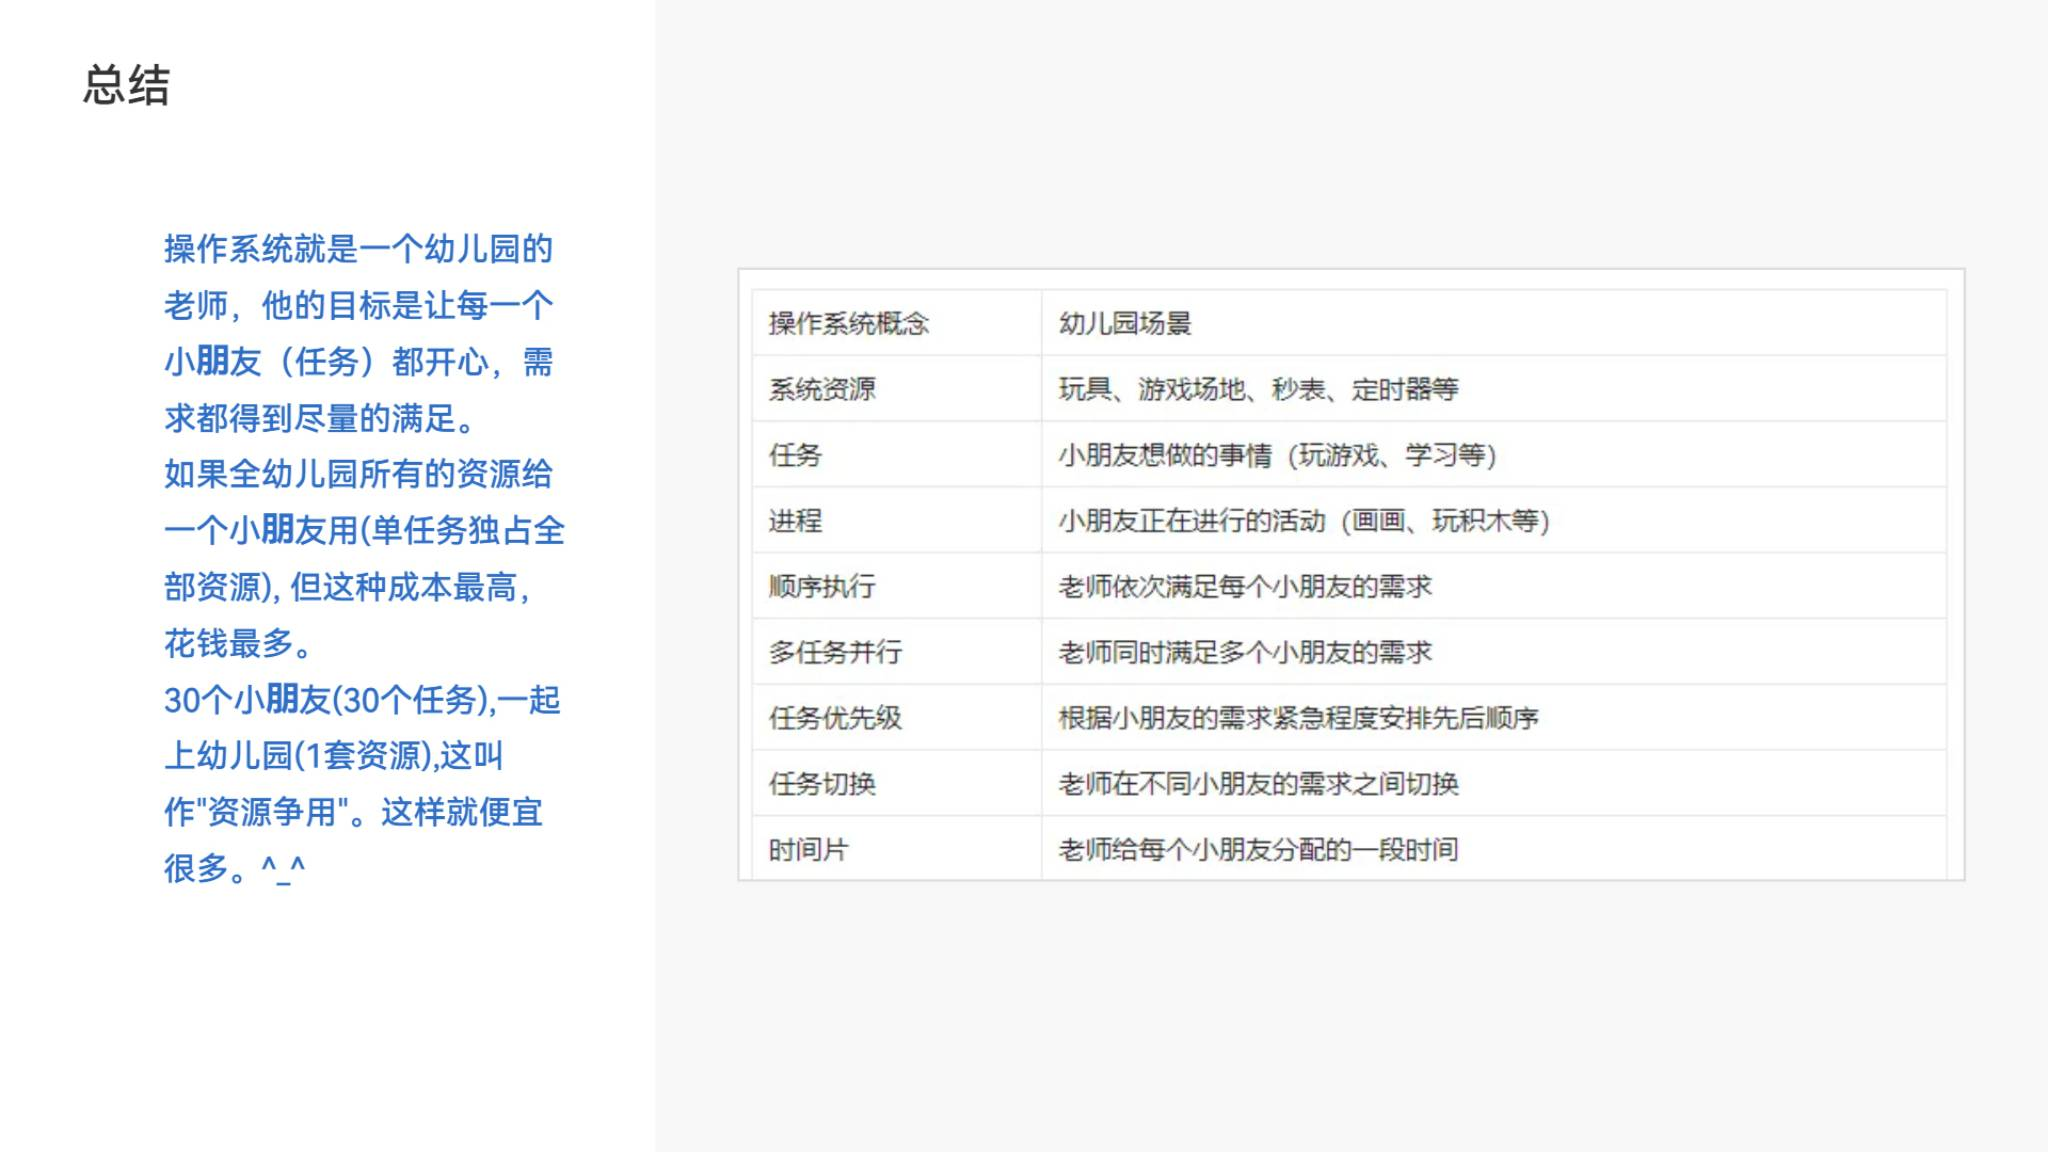

*来源：配套讲义第 12 页，原始在线预览图。*

**补充理解：**类比帮助理解职责，不能逐字代替硬件规则。老师可能同时组织多项活动；在本课程关心的单核任务模型中，同一时刻只运行一个任务执行流，多个任务通过交替执行形成并发。


## 6. 顺序执行、并发与并行

讲义第 2、12 页介绍顺序执行与“多任务并行”。为了学习单核任务切换，这里补充区分**并发**和**并行**。

| 方式 | 含义 | 简化示意 |
|---|---|---|
| 顺序执行 | 一项完成后才做下一项 | A 完成 → B 完成 → C 完成 |
| 并发 | 一段时间内多项任务交替推进 | A 一段 → B 一段 → A 一段 |
| 并行 | 多项工作在同一时刻实际执行 | 核心 1 做 A，核心 2 做 B |

```text
单核交替执行：时间 →
CPU： [ A ][ B ][ C ][ A ][ B ]

两个核心并行：时间 →
核1： [ A ][ A ][ A ]
核2： [ B ][ B ][ B ]
```

**补充理解：**单核 CPU 的时间片轮转不是让两个任务同时占用同一个执行核心。外设、DMA 或其他处理单元可能与 CPU 同时工作，但这是另一个层次的硬件并行。

快速切换可以改善多个任务的响应，不会凭空增加 CPU 的计算总能力，切换本身还需要时间。


## 7. 任务不是只有“运行”和“停止”

以下是**补充理解**：用常见的三状态模型分析调度，实际内核还可能有挂起、终止等状态。

| 状态 | 含义 | 是否应被选中运行？ |
|---|---|---|
| 就绪 Ready | 已具备运行条件，等待 CPU | 可以 |
| 运行 Running | 当前获得 CPU | 当前正在运行 |
| 阻塞 Blocked | 等待时间、事件或资源 | 条件满足前不应运行 |

```text
就绪 ──被调度──→ 运行
 ↑              │
 │              ├──时间片结束/被抢占──→ 就绪
 │              │
 └──等待条件满足─阻塞 ←──等待事件/睡眠──┘
```

例如，通信任务等待下一帧数据时，可以阻塞；收到数据后进入就绪状态。**就绪不等于立刻执行**，还要由调度器决定何时获得 CPU。

同样，睡眠到期通常只是变为就绪，并不保证在那一时刻准确执行下一条指令。这为第 04—05 篇的延时问题提供了概念基础。


## 8. 时间片与轮转：每人先做一小段

讲义第 12 页把时间片类比为老师分配给每个小朋友的一段时间。

**补充理解：**时间片是允许任务连续占用 CPU 的一段预算。轮转策略让符合条件的任务依次运行；任务提前阻塞或完成时，不必把剩余时间片耗尽。

下面是**自编例子**：A、B、C 同时就绪，需要的 CPU 时间分别为 6、4、2 ms，时间片为 2 ms。忽略所有切换和中断开销，不考虑优先级。

| 时间区间 | 运行任务 | A 剩余 | B 剩余 | C 剩余 |
|---|---|---:|---:|---:|
| 0—2 ms | A | 4 | 4 | 2 |
| 2—4 ms | B | 4 | 2 | 2 |
| 4—6 ms | C | 4 | 2 | 0，完成 |
| 6—8 ms | A | 2 | 2 | 已完成 |
| 8—10 ms | B | 2 | 0，完成 | 已完成 |
| 10—12 ms | A | 0，完成 | 已完成 | 已完成 |

```text
时间：0    2    4    6    8    10   12 ms
CPU： | A  | B  | C  | A  | B  | A  |
```

三项工作仍然共需 12 ms CPU 时间。轮转改变了推进顺序：B 和 C 可以较早开始，C 在第 6 ms 完成，而不是一直等到 A、B 全部结束。

时间片越小，通常切换越频繁；越大，某些任务等待下一次机会越久。应结合响应要求与切换成本选择。定时器 tick 是计时事件，一段时间片也可以由多个 tick 组成，两者不必相等。


## 9. 上下文切换：记住“在哪里”和“算到哪里”

讲义第 13 页说明：切换前记录当前任务状态，方便一会儿接着继续执行。这就是上下文保存的核心目的。

**补充理解：**执行上下文通常涉及：

| 信息 | 为什么需要 |
|---|---|
| 继续执行的位置，如 PC 或返回地址 | 回到正确的指令位置 |
| 寄存器中的值 | 恢复未完成的计算和临时结果 |
| 栈指针 SP 与任务栈 | 找回调用链、返回地址和保存的数据 |
| 必要的状态寄存器 | 恢复标志、寄存器组等相关状态 |

```text
A 运行 → 保存 A 的上下文 → 选择 B
      → 恢复 B 的上下文 → B 从原位置继续
```

不同架构、调用约定和切换入口需要保存的内容不同；有些状态由硬件自动保存，有些由软件完成。不能认为“只改一个指针”就能在所有系统中完成可靠切换，也不能把课堂后续代码中的保存清单未经检查推广到其他 MCU。

普通函数调用通常在同一任务内完成；任务切换则要让另一个执行流继续工作。二者都可能利用栈，但管理目的不同。


## 10. 谁决定下一项工作？

以下为**补充理解**：调度策略与切换时机需要分别分析。

| 概念 | 核心问题 |
|---|---|
| 轮转 | 符合条件的任务怎样轮流获得机会？ |
| 优先级调度 | 哪些任务应优先运行？ |
| 协作式切换 | 当前任务何时主动让出 CPU？ |
| 抢占式切换 | 系统何时可以暂停当前任务、运行另一任务？ |

这些机制可以组合。例如，一个系统可以优先运行高优先级就绪任务，再对同优先级任务进行时间片轮转。

高优先级任务若长期持续占用 CPU，低优先级任务可能很难得到机会，这称为饥饿。优先级应该根据任务的时间和依赖要求设计，而不是简单按“功能看起来重要”随意赋值。

当前任务阻塞、主动让出、时间片到期或某个更高优先级任务变为就绪，都可能成为调度时机，具体取决于内核设计。这里介绍通用概念，不断言后续课程的简化实现已经包含所有策略。


## 11. CPU 调度与资源管理

讲义第 2 页把资源争用描述为多个任务需要共享有限资源，第 12—13 页强调协调和安排轮流使用。

**补充理解：**CPU 调度回答“谁来运行”；资源管理回答“谁可以访问什么，访问怎样协调”。二者不能互相代替。

| 资源 | 常见问题 | 协调思路 |
|---|---|---|
| CPU | 多个就绪任务都想运行 | 调度策略 |
| 共享变量/缓冲区 | 读写交错导致状态不一致 | 临界区、同步机制 |
| 串口 | 两个任务的输出混在一起 | 串行化发送或专门发送任务 |
| I²C 等外设接口 | 一次事务中途被另一任务打断 | 保护完整事务、明确资源归属 |
| 内存 | 可用容量有限、对象使用关系不清楚 | 分配规则、生命周期和边界检查 |

按时间片把 CPU 分给两个任务，并不自动保证它们对外设的多步操作不会交错。外设事务和数据结构都需要额外的访问规则。


## 12. 资源争用与竞态：两个任务都加一，结果却只加了一

以下为**自编例子**。两个任务都执行 `count = count + 1`，假设它实际被分成“读取、加一、写回”三个步骤，且步骤之间可能发生切换。

初始 `count = 0`：

| 步骤 | 发生的动作 | 共享 count |
|---|---|---:|
| 1 | A 读取 0，计算自己的临时结果 1 | 0 |
| 2 | 切到 B；B 也读取 0，计算临时结果 1 | 0 |
| 3 | A 写回 1 | 1 |
| 4 | B 写回 1，覆盖 A 的更新 | 1 |

期望结果是 2，实际结果却是 1。这是丢失更新，说明结果依赖执行交错，构成竞态问题。**单核也会出现竞态**，任务切换或中断就可以制造交错，不必有两个核心。

资源争用是需要共享资源的情况，并不必然错误；竞态是访问缺少必要协调，导致结果依赖时序。正确的共享设计可以管理争用。

**补充理解：**`volatile` 不能把一组读改写操作变成原子操作，也不能代替互斥。实际是否原子，要根据目标机器的指令和内存模型判断。


## 13. 临界区、互斥和事件通知

以下为**补充理解**，介绍后面分析外设访问时会用到的工具。

| 机制 | 主要用途 | 注意点 |
|---|---|---|
| 临界区 | 保护不能被相关访问打断的一段代码 | 范围要尽量短 |
| 互斥锁 | 同一时刻只允许一个持有者访问资源 | 获取和释放必须配对，依实现处理等待 |
| 信号量/事件 | 通知某个条件发生或管理许可数量 | 与资源所有权不是完全同一概念 |
| 队列 | 传递数据或请求，减少直接共享 | 明确容量和满队列处理方式 |

在某些单核裸机或简化内核中，短暂屏蔽相关中断可以保护特定访问，但会增加中断响应延迟；它也不是通用的多核互斥方法。不能把整段通信或长时间延时都放进这种临界区。

很多内核的中断处理函数不能调用可能阻塞等待的普通接口，需要使用规定的中断专用接口。这些规则应以实际内核文档为准。

**死锁的直观例子：**A 占用资源 X，等待 B 占用的 Y；B 占用 Y，又等待 A 占用的 X。双方都无法继续。统一获取顺序、缩短持有时间和按设计使用超时，有助于减少这类问题，但不能仅靠加时间片解决。


## 14. 中断：暂停当前流程，处理需要响应的事件

讲义第 13 页用“小朋友摔倒，老师暂停当前活动”类比中断。

**补充理解：**定时器、串口接收等事件可以提出中断请求。处理器在允许响应、满足相应条件时转入中断处理程序。

```text
任务正在执行
   ↓ 出现中断请求，并满足响应条件
保存必要的返回信息 → 执行中断处理程序
   ↓
按系统机制返回原任务，或在调度后转到另一任务
```

中断处理和任务切换是不同概念：一次中断可以处理完就返回原任务，也可能唤醒任务并引发调度。不是每次中断都必须切换任务。

中断也不是无等待的“立刻响应”。中断屏蔽、优先级、当前执行条件与处理开销都会影响响应时间。常见做法是在中断里完成必要的短操作，把较长处理交给任务。

定时器中断提供计时和调度机会；**单纯开启定时器，不会自动产生一个完整操作系统**，还要有任务状态、上下文与调度规则。


## 15. 实时操作系统：结果正确，还要按时完成

讲义第 13 页区分实时、非实时以及硬实时、软实时。关注点是完成任务的时间要求。

| 类型 | 时间要求 | 补充例子 |
|---|---|---|
| 硬实时 | 超过截止时间不可接受 | 具有严格期限的保护或控制动作 |
| 软实时 | 偶尔超时可以容忍，但服务质量下降 | 音视频播放、某些界面更新 |
| 非实时目标 | 不以严格截止时间作为主要要求 | 普通批处理任务 |

**补充理解：**实时不等于“很快”。一个任务每次都在 5 ms 内完成，若期限为 10 ms，可以满足时间要求；另一个任务平均 1 ms、偶尔 20 ms，若期限为 10 ms，仍可能失败。

| 时间指标 | 含义 |
|---|---|
| 周期 | 任务多久需要执行一次 |
| 截止时间 | 本次工作最晚何时必须完成 |
| 执行时间 | 工作实际占用 CPU 多久 |
| 响应时间 | 从请求或释放到工作完成多久，包括等待 |
| 抖动 | 启动、响应或输出时刻的变化 |

RTOS 提供适合可预测响应的机制，但不能单凭使用 RTOS 就保证期限。还要分析执行时间、优先级、临界区、中断、共享资源和负载。轮转体现公平机会，也不自动保证所有任务满足截止时间。


## 16. 用机器人任务理解负载与响应

以下为**自编例子**，参数仅用于计算，不是课程设备的实测值。

| 任务 | 周期 | 每次 CPU 时间 | 示例关注点 |
|---|---:|---:|---|
| 电机控制 | 10 ms | 1 ms | 在下一次周期前完成本轮更新 |
| 传感器整理 | 50 ms | 2 ms | 按时提供数据 |
| 状态显示 | 100 ms | 3 ms | 可适当降低更新频率 |
| 串口接收 | 事件触发 | 依数据量而定 | 避免缓冲区溢出 |

忽略中断、切换和其他开销，前三项的平均 CPU 负载为：

```text
U = 1/10 + 2/50 + 3/100 = 0.17 = 17%
```

这说明三项周期工作平均占用的 CPU 比例。**17% 不能证明任何一次响应都满足期限**：串口突发负载、长临界区或高优先级任务占用仍可能延误电机控制。

分析实际设备时，要同时回答：任务什么时候变为就绪、最长需要运行多久、会等待哪些资源、谁能抢占它、截止时间是多少。平均利用率只是检查的一部分。


## 17. 从裸机循环到内核调度

以下是**补充伪代码**，只表达组织方式，不是可直接编译的 STC 程序，也不是课程 API。

一个简单裸机循环可以这样组织：

```text
循环：
    如果控制周期到期：执行一次短控制步骤
    如果收到数据：处理一小段接收数据
    如果显示周期到期：更新显示
```

如果每项操作足够短、没有长时间忙等，这种方式也可以交替推进多项工作。它不要求任务各有独立栈。

使用内核时，任务可以表达成各自的执行流：

```text
控制任务：循环执行一次控制步骤，然后等待下一个周期
通信任务：等待接收事件，处理数据，再继续等待
显示任务：更新界面，然后等待下一次更新

内核：管理就绪/等待状态，选择任务，保存和恢复上下文
```

忙等是在等待时继续执行指令，占用 CPU；阻塞等待则让出运行机会。后续课程将进一步讨论具体延时与 sleep 实现，本篇不预先断言它们已经采用完整 RTOS 的阻塞机制。


## 18. 高级系统功能与本课程的边界

视频 03 的标题是“高级操作系统特性”。本篇未逐段核验该视频，下面是**通用补充概览**，不作为它的逐项内容清单。

| 功能 | 解决什么 | 是否所有嵌入式内核都具备？ |
|---|---|---|
| 任务优先级、计时和同步 | 管理多执行流和等待关系 | 具体功能依内核而定 |
| 内存保护与进程隔离 | 限制错误影响范围 | 依硬件和系统支持 |
| 虚拟内存 | 提供地址映射等管理能力 | 许多 MCU 系统没有 |
| 文件系统 | 组织持久化数据 | 可以没有，也可以按需加入 |
| 网络协议栈和设备服务 | 提供通信与设备功能 | 可作为独立组件集成 |

课程后面的重点是 STC 上的任务堆栈、执行顺序切换、调度与延时。学会一个简化多任务机制，是理解更完整内核的入口；功能清单不能仅凭“操作系统”这个名称推断。


## 19. 讲义总结与一页复习表

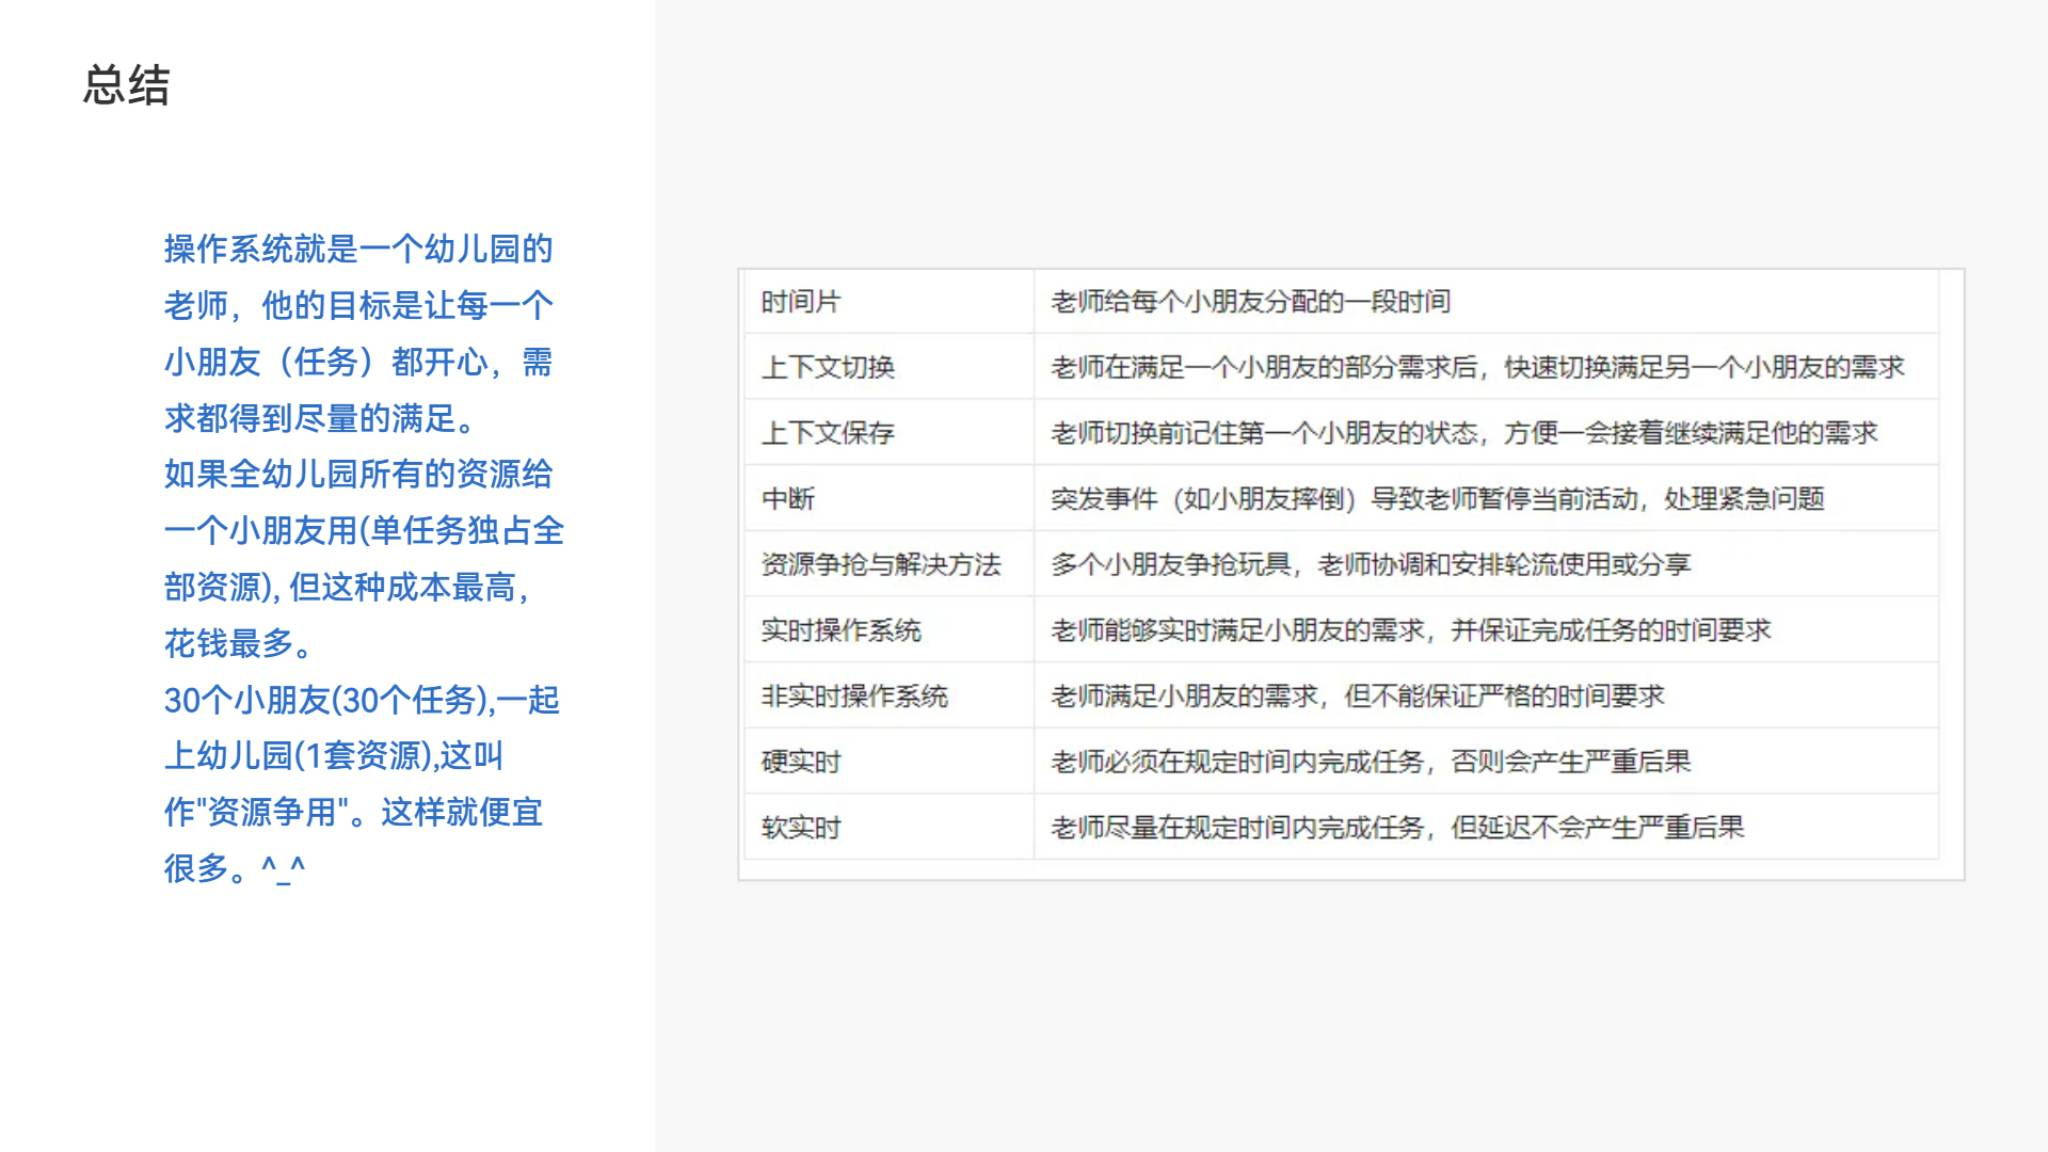

*来源：配套讲义第 13 页，原始在线预览图。*

| 知识点 | 复习时要说清楚 |
|---|---|
| 操作系统 | 按规则组织执行和管理有限资源 |
| 任务 | 工作或内核管理的执行实体，术语依系统而定 |
| 单核并发 | 交替执行多个任务，不等于同核同时执行 |
| 就绪与阻塞 | 有运行条件 / 等待条件，不应混同 |
| 时间片 | 连续使用 CPU 的预算，不等于任务完成时间 |
| 上下文 | 恢复执行位置、寄存器、栈与必要状态 |
| 调度 | 选择合适的可运行任务 |
| 资源争用 | 多任务需要共享有限资源 |
| 竞态 | 缺少协调，使结果依赖访问交错 |
| 互斥 | 防止相关资源被不允许地同时或交错访问 |
| 中断 | 事件引起的控制转移，不必然切换任务 |
| 实时性 | 在规定时间内完成，不能只看平均速度 |
| 简化内核 | 可能只具备部分管理能力，不自动拥有完整系统功能 |


## 20. 自测与参考答案

先遮住答案，用自己的话回答。

1. CPU 控制单元与操作系统调度器各自负责什么？
2. 一个单核 CPU 通过轮转执行两个任务，属于并发还是同核并行？
3. 一个任务等待串口数据时，就绪和阻塞有什么区别？
4. 时间片为 2 ms，是否每个任务都必须执行满 2 ms？
5. 第 8 节中 C 何时完成？A 何时完成？总 CPU 工作量减少了吗？
6. 为什么切换任务时不能只记住“任务名字”？
7. 单核系统是否可能出现共享计数器丢失更新？
8. 分配了时间片，是否就保护了完整的外设事务？
9. 一次中断处理完毕，是否必须运行另一个任务？
10. RTOS 是否自动保证所有任务按时完成？
11. 睡眠到期是否表示任务立即在该时刻开始运行？
12. 平均 CPU 负载只有 17%，为什么仍可能错过控制期限？

### 参考答案

1. 控制单元安排单条机器指令内的数据与状态动作；调度器决定可运行任务获得执行机会的顺序。
2. 在本篇模型中属于交替推进的并发；同核并行不是这个轮转模型的含义。
3. 就绪意味着具备运行条件；阻塞意味着还在等待，条件满足前不应被选中运行。
4. 不必须。任务可以提前完成、阻塞或主动让出。
5. C 在 6 ms、A 在 12 ms 完成；总工作量仍为 12 ms，实际切换还会增加开销。
6. 还要恢复继续执行的位置、未完成计算和栈等状态，否则无法正确接着运行。
7. 可以。任务切换或中断能让读改写步骤交错，产生丢失更新。
8. 没有。CPU 调度与资源访问保护是不同问题，需要额外协调事务。
9. 不必须。可以返回原任务，也可能在满足调度条件时转到其他任务。
10. 不会。期限取决于执行时间、调度、共享资源、中断和整体负载等。
11. 通常只是变为就绪，实际运行还需要获得 CPU。
12. 平均值不能约束每次等待；长临界区、突发负载和优先级安排都可能增加响应时间。

### 计算练习

三个任务同时就绪，各需 3 ms CPU 时间，时间片为 1 ms，无优先级差异、无阻塞，忽略所有开销，按 A→B→C 轮转。各自何时完成？

**答案：**执行顺序为 A、B、C、A、B、C、A、B、C。A 在 7 ms、B 在 8 ms、C 在 9 ms 完成。注意最后一轮各自的结束时刻，与总工作量 9 ms 不同。


## 21. 五篇规划、课程对应与下一篇

| 编号 | 笔记标题 | 对应视频 |
|---|---|---|
| 01 | 操作系统基础、多任务与资源调度 | 01—08 |
| 02 | STC内存、任务堆栈与任务切换原理 | 09—13 |
| 03 | 任务调度器与上下文保护 | 14—15 |
| 04 | 多任务外设访问与延时问题 | 16—17 |
| 05 | sleep实现与定时时间片轮转 | 18—19 |

本篇资料对应：

| 本篇内容 | 视频主题 | 已核对讲义 |
|---|---|---|
| 基础概念与幼儿园类比 | 01—03、08 | 第 2、12 页 |
| 时间片、上下文、资源调度 | 04—06、08 | 第 12—13 页的总结定义 |
| 中断、实时与硬/软实时 | 07—08 | 第 13 页的总结定义 |
| 状态模型、竞态例子、负载和伪代码 | 用于扩展上述主题 | 自编补充，非讲义原例 |

来源：[《自己动手写嵌入式操作系统》课程资料](https://pan.baidu.com/s/1BaPETt4F3Xnew179lHT4DA?pwd=9988)，提取码 `9988`。资料目录为“3、自己动手写嵌入式操作系统”；讲义为 `ppt/自己动手写嵌入式操作系统.pdf`，共 16 页。

下一篇进入具体硬件：任务栈放在哪里，SP 怎样与调用/返回关联，以及怎样创建任务的初始执行状态。本篇先记住这条关系：

```text
多项工作需要推进 → 选择可运行任务 → 保存/恢复上下文
                → 协调共享资源 → 检查时间要求
```
